# Direct and indirect ISN helium beams as a probe of the ionization rate — figures

This notebook makes every figure in the repository from the data products
written by the scripts in `scripts/` (run `bash scripts/run_all.sh` first).
Figures are saved to `figures/`.

**Question.** Antonik et al. (2025, ApJ 995, 57) find, from New Horizons/SWAP
He⁺ pickup ions, an ISN He ionization rate ≈43% above the model, consistent
with the IBEX-Lo result of Swaczyna et al. (2022). Pickup-ion and direct-beam
fluxes both depend on the product of the ISN density, ionization survival and
(for IBEX/IMAP-Lo) a poorly known absolute detection efficiency. Can the ratio
of the **indirect** to the **direct** ISN He beam measured by IMAP-Lo separate
"more ionization" from "more helium"?

**Key relation.** For β(r) = β₀ (1 au / r)², the survival probability along a
Keplerian orbit is exp(−β₀ X) with X = (1 au)² Δν / h (Δν: angle swept from
infinity, h: angular momentum). Hence

$$\ln\frac{F_\mathrm{ind}}{F_\mathrm{dir}} = \text{const} - \beta_0\left(\langle X\rangle_\mathrm{ind}-\langle X\rangle_\mathrm{dir}\right),$$

independent of the ISN density and, for a common instrument, of its absolute
efficiency.

In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

import isnhe
from isnhe import (InflowParams, angular_distance, effective_exposure,
                   log_interp_beta, counts_needed, poisson_deviance, scan_circle,
                   SkyGrid)
from isnhe.constants import GM_SUN, AU_KM

DATA, FIGS = REPO / "data", REPO / "figures"
FIGS.mkdir(exist_ok=True)

# ---- style ---------------------------------------------------------------
C_DIR, C_IND, C_ALT = "#2a78d6", "#eb6834", "#1baf7a"   # validated categorical slots 1-3
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2.0, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")

# ---- observer longitude <-> calendar date (low-precision solar ephemeris) ---
def earth_longitude_on(dates):
    jd0 = np.datetime64("2000-01-01T12:00")
    n = (dates - jd0) / np.timedelta64(1, "D")
    L = 280.460 + 0.9856474 * n
    g = np.deg2rad(357.528 + 0.9856003 * n)
    lam_sun = L + 1.915 * np.sin(g) + 0.020 * np.sin(2 * g)
    return (lam_sun + 180.0) % 360.0

MONTHS = np.arange("2026-01", "2027-01", dtype="datetime64[M]").astype("datetime64[m]")
MONTH_LON = earth_longitude_on(MONTHS)
MONTH_LBL = [str(m.astype(object).strftime("%b")) for m in MONTHS.astype("datetime64[D]")]

def add_month_axis(ax):
    top = ax.secondary_xaxis("top")
    top.set_xticks(MONTH_LON, MONTH_LBL)
    top.tick_params(colors=INK2, labelsize=8)
    return top

# ---- data ----------------------------------------------------------------
ann = np.load(DATA / "annual_beams.npz")
meta = json.loads(str(ann["meta"]))
P = InflowParams(**meta["params"])
L, B = ann["obs_lons"], ann["betas"]
EMINS = ann["emins"]
Fd_all, Fi_all = ann["F_dir"], ann["F_ind"]     # (emin, lon, beta)
Fd, Fi = Fd_all[0], Fi_all[0]                    # no energy threshold

BETA_MODEL = 1.0e-7          # model (TIMED/F10.7-like) rate at 1 au, s^-1
ENH = 1.43                   # Antonik et al. (2025): SWAP / model
BETA_ENH = ENH * BETA_MODEL
LON_DIR, LON_IND = 130.0, 30.0   # reference seasons (Feb: direct; late Oct: indirect)

def at_lon(table, lon):
    i = int(np.argmin(np.abs(((L - lon) + 180) % 360 - 180)))
    return table[i]

print(f"inflow parameters: {P}")
print(f"observer longitudes: {L.size} ({L[1]-L[0]} deg step), betas: {B.min():.1e}..{B.max():.1e}")

inflow parameters: InflowParams(density=0.015, speed=25.4, lon=255.7, lat=5.1, temperature=7500.0)
observer longitudes: 144 (2.5 deg step), betas: 0.0e+00..3.0e-07


## Fig. 1 — Direct and indirect trajectories (cold-model sketch)

Two hyperbolic orbits pass through every point inside the heliosphere. The
direct one sweeps less than 180° from infinity; the indirect one wraps around
the Sun and spends longer in the region of strong ionization. Shown for a
cold (T = 0) gas in the plane of the inflow; the inflow arrives from the right.
In the cold model the impact parameters solve
$b^2 - r\sin\psi\, b - (GM r/u^2)(1-\cos\psi) = 0$, with ψ the polar angle of the
point measured from the upwind direction.

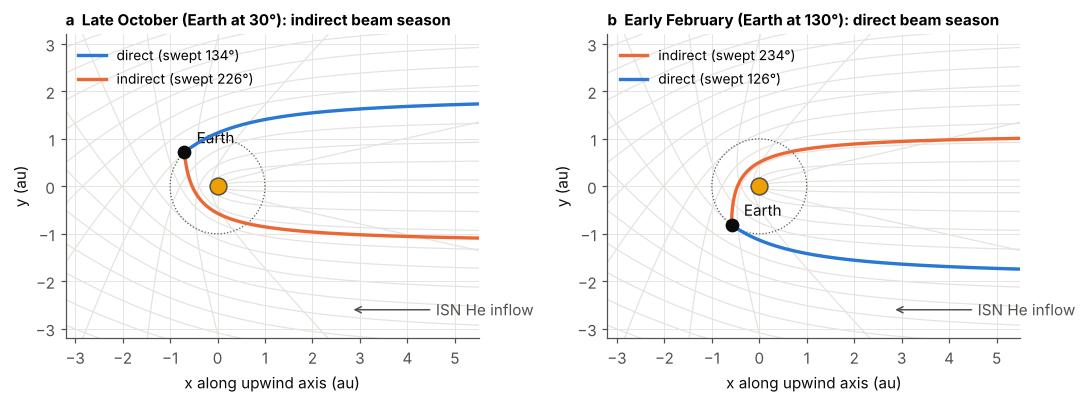

In [2]:
u = P.speed
Lg = GM_SUN / AU_KM / u**2          # GM/u^2 in au

def impact_parameters(r, psi):
    s = r * np.sin(psi) / 2
    root = np.sqrt(s**2 + Lg * r * (1 - np.cos(psi)))
    return s + root, s - root          # b > 0 (counter-clockwise), b < 0 (clockwise)

def trajectory(b, psi_end=None, n=2000):
    # 1/r = (L/b^2)(1 - cos psi) + sin(psi)/b ; psi runs from 0 in the sense of motion
    if b > 0:
        psi = np.linspace(1e-4, 2 * np.pi, n)
    else:
        psi = -np.linspace(1e-4, 2 * np.pi, n)
    inv_r = Lg / b**2 * (1 - np.cos(psi)) + np.sin(psi) / b
    ok = inv_r > 0
    first_bad = np.argmax(~ok) if (~ok).any() else n
    psi, r = psi[:first_bad], 1 / inv_r[:first_bad]
    if psi_end is not None:
        keep = np.abs(psi) <= np.abs(psi_end)
        psi, r = psi[keep], r[keep]
    return r * np.cos(psi), r * np.sin(psi)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.9))
for ax, obs_lon, title in zip(axes, [LON_IND, LON_DIR],
                              ["a  Late October (Earth at 30°): indirect beam season",
                               "b  Early February (Earth at 130°): direct beam season"]):
    for bb in np.concatenate([np.linspace(-5, -0.15, 12), np.linspace(0.15, 5, 12)]):
        x, y = trajectory(bb)
        ax.plot(x, y, color=GRID, lw=0.8, zorder=1)
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color=INK2, lw=0.8, ls=":", zorder=2)
    ax.plot(0, 0, "o", ms=11, color="#eda100", mec=INK2, zorder=5)
    ax.annotate("ISN He inflow", xy=(2.8, -2.6), xytext=(4.6, -2.6), color=INK2,
                arrowprops=dict(arrowstyle="->", color=INK2), va="center")

    psi_E = np.deg2rad((obs_lon - P.lon) % 360)
    xe, ye = np.cos(psi_E), np.sin(psi_E)
    bp, bm = impact_parameters(1.0, psi_E)
    for b_, psi_end in [(bp, psi_E), (bm, psi_E - 2 * np.pi)]:
        swept = abs(np.rad2deg(psi_end))
        direct = swept < 180
        x, y = trajectory(b_, psi_end)
        col = C_DIR if direct else C_IND
        lbl = f"{'direct' if direct else 'indirect'} (swept {swept:.0f}°)"
        ax.plot(x, y, color=col, lw=2.2, zorder=4, label=lbl)
        assert np.hypot(x[-1] - xe, y[-1] - ye) < 0.02   # orbit really hits Earth
    ax.plot(xe, ye, "o", ms=8, color=INK, zorder=6)
    ax.annotate("Earth", (xe, ye), xytext=(8, 6), textcoords="offset points", color=INK)
    ax.set_xlim(-3.2, 5.5); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
    ax.set_xlabel("x along upwind axis (au)"); ax.set_ylabel("y (au)")
    ax.set_title(title, fontsize=10)
    ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "fig1_trajectories")

## Fig. 2 — Model check: ISN He density at 1 au

Density along Earth's orbit for several ionization rates, split into direct
and indirect atoms. Far from the Sun the model returns the input density
(tested in `tests/`); upwind at 1 au with β₀ ≈ 1×10⁻⁷ s⁻¹ it gives ≈0.011 cm⁻³,
consistent with the ≈0.01 cm⁻³ adopted by Swaczyna et al. (2025, ApJS 277, 17)
for solar minimum. The downwind peak is the gravitational focusing cone.

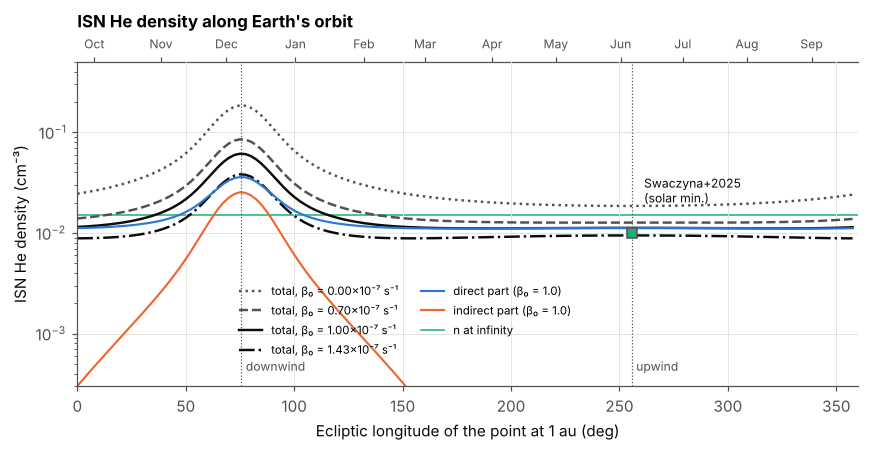

In [3]:
den = np.load(DATA / "density_profile.npz")
lons_d, betas_d = den["lons"], den["betas"]
fig, ax = plt.subplots(figsize=(8, 4.2))
styles = {0.0: (INK2, ":"), 0.7e-7: (INK2, "--"), 1.0e-7: (INK, "-"), 1.43e-7: (INK, "-.")}
for j, b in enumerate(betas_d):
    col, ls = styles.get(round(b, 12), (INK2, "-"))
    ax.plot(lons_d, den["n_all"][:, j], color=col, ls=ls, lw=1.6,
            label=f"total, β₀ = {b*1e7:.2f}×10⁻⁷ s⁻¹")
jm = int(np.argmin(np.abs(betas_d - BETA_MODEL)))
ax.plot(lons_d, den["n_dir"][:, jm], color=C_DIR, lw=1.4, label="direct part (β₀ = 1.0)")
ax.plot(lons_d, den["n_ind"][:, jm], color=C_IND, lw=1.4, label="indirect part (β₀ = 1.0)")
ax.axhline(P.density, color=C_ALT, lw=1.0, zorder=0, label="n at infinity")
ax.set_ylim(3e-4, 0.5)
for x, t in [(P.lon, "upwind"), ((P.lon + 180) % 360, "downwind")]:
    ax.axvline(x, color=INK2, lw=0.8, ls=":")
    ax.text(x + 2, 4e-4, t, color=INK2, fontsize=8, va="bottom")
ax.errorbar([P.lon], [0.010], fmt="s", ms=6, color=C_ALT, mec=INK2, zorder=6)
ax.annotate("Swaczyna+2025\n(solar min.)", (P.lon, 0.010), xytext=(8, 20),
            textcoords="offset points", fontsize=8, color=INK)
ax.set_yscale("log")
ax.set_xlabel("Ecliptic longitude of the point at 1 au (deg)")
ax.set_ylabel("ISN He density (cm⁻³)")
ax.set_xlim(0, 360)
ax.legend(fontsize=7.5, ncol=2, loc="lower center", bbox_to_anchor=(0.42, 0.06))
ax.set_title("ISN He density along Earth's orbit")
add_month_axis(ax)
fig.tight_layout(); save(fig, "fig2_density_1au")

## Fig. 3 — Where the beams are on the sky

Directional flux in the observer frame (arrival directions, ecliptic
coordinates; Earth's orbital motion included). Grey shading is the total flux;
coloured contours trace the direct (blue) and indirect (orange) beams at
1, 10 and 50% of each beam's peak. The dashed curve is the circle seen by a
detector with boresight 90° from a Sun-pointing spin axis (IBEX-Lo); the solid
curve is the pivot angle that crosses the indirect beam centroid (IMAP-Lo's
pivot platform can tilt the boresight). In October the broad blue patch is
the slow (~10 eV) direct population overtaking Earth from behind; in February
the indirect beam arrives from within a few degrees of the Sun and cannot be
observed.

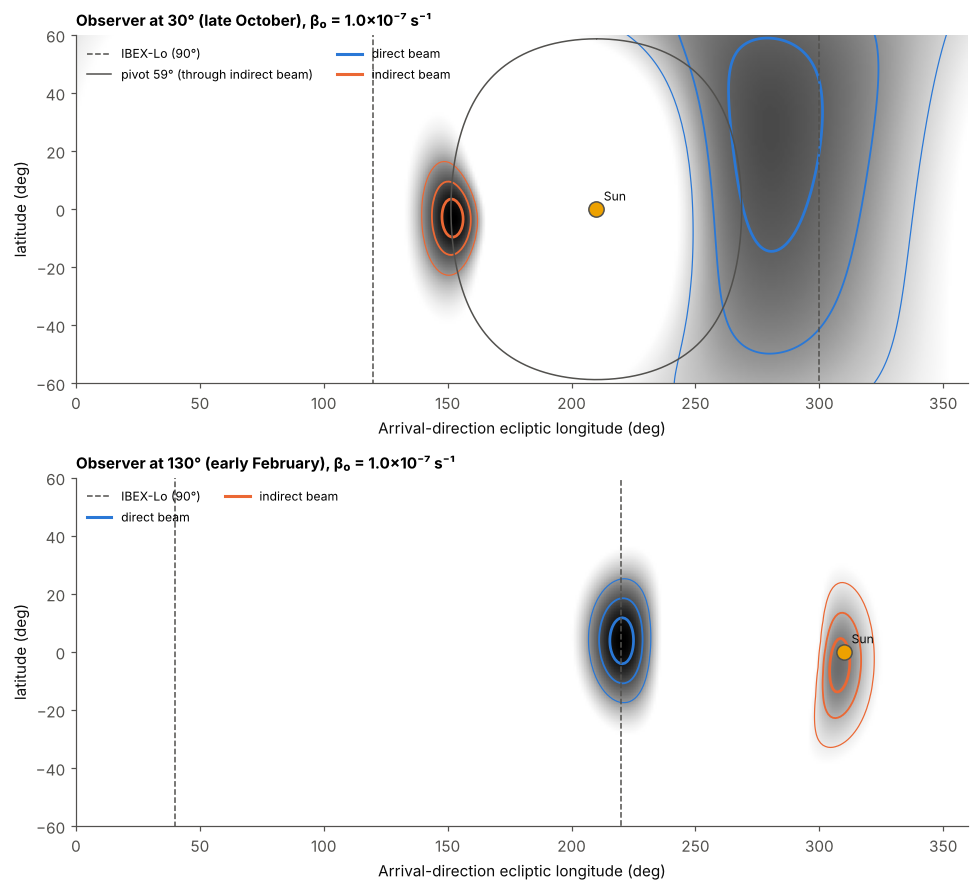

In [4]:
sky = np.load(DATA / "skymaps.npz")
grid = SkyGrid(json.loads(str(sky["meta"]))["grid"]["dang"])
jb = int(np.argmin(np.abs(sky["betas"] - BETA_MODEL)))
show = [LON_IND, LON_DIR]
fig, axes = plt.subplots(2, 1, figsize=(9, 8.2))
for ax, olon in zip(axes, show):
    k = int(np.argmin(np.abs(sky["obs_lons"] - olon)))
    md_, mi_ = sky["direct"][k, jb], sky["indirect"][k, jb]
    tot = md_ + mi_
    ax.imshow(np.where(tot > 0, tot, np.nan), origin="lower", aspect="auto",
              extent=[0, 360, -90, 90], cmap="Greys",
              norm=LogNorm(vmin=tot.max() * 1e-4, vmax=tot.max()))
    for m, col in [(md_, C_DIR), (mi_, C_IND)]:
        ax.contour(grid.lon, grid.lat, m, levels=m.max() * np.array([0.01, 0.1, 0.5]),
                   colors=col, linewidths=[0.8, 1.2, 1.8])
    sun_lon = (olon + 180) % 360
    ax.plot(sun_lon, 0, "o", ms=10, color="#eda100", mec=INK2)
    ax.text(sun_lon + 3, 3, "Sun", fontsize=8, color=INK)
    # scan circles
    circles = [(90.0, "--", "IBEX-Lo (90°)")]
    if olon == LON_IND:
        ci = at_lon(ann["cen_ind"], olon)
        piv = float(angular_distance(sun_lon, 0.0, ci[0], ci[1]))
        circles.append((piv, "-", f"pivot {piv:.0f}° (through indirect beam)"))
    for pv, ls, lab in circles:
        _, clon, clat, _ = scan_circle(tot, grid, olon, pv, n_points=1440)
        jumps = np.where(np.abs(np.diff(clon)) > 10)[0]
        segs = np.split(np.arange(clon.size), jumps + 1)
        for s_ in segs:
            ax.plot(clon[s_], clat[s_], ls=ls, color=INK2, lw=1.0)
        ax.plot([], [], ls=ls, color=INK2, lw=1.0, label=lab)
    ax.plot([], [], color=C_DIR, label="direct beam"); ax.plot([], [], color=C_IND, label="indirect beam")
    ax.set_xlim(0, 360); ax.set_ylim(-60, 60)
    ax.set_xlabel("Arrival-direction ecliptic longitude (deg)")
    ax.set_ylabel("latitude (deg)")
    date = {LON_IND: "late October", LON_DIR: "early February"}[olon]
    ax.set_title(f"Observer at {olon:.0f}° ({date}), β₀ = {sky['betas'][jb]*1e7:.1f}×10⁻⁷ s⁻¹", fontsize=10)
    ax.legend(fontsize=8, loc="upper left", ncol=2)
    ax.grid(False)
fig.tight_layout(); save(fig, "fig3_skymaps")

## Fig. 4 — The two beams over the year

(a) Sky-integrated beam fluxes for the model rate (solid) and the 43% higher
rate (dashed). (b) Flux-weighted mean energy in the spacecraft frame — the
direct beam in February (~130 eV) and the indirect beam in October–November
(~100–110 eV) have similar energies, so an energy-dependent detection
efficiency largely cancels in their ratio. (c) Angle between the beam centroid
and the Sun, i.e. the boresight-to-spin-axis angle needed to see the beam
centre with a Sun-pointing spinner. Grey bands: the beam centroids are
closer than the sum of their RMS widths (beams not separable).

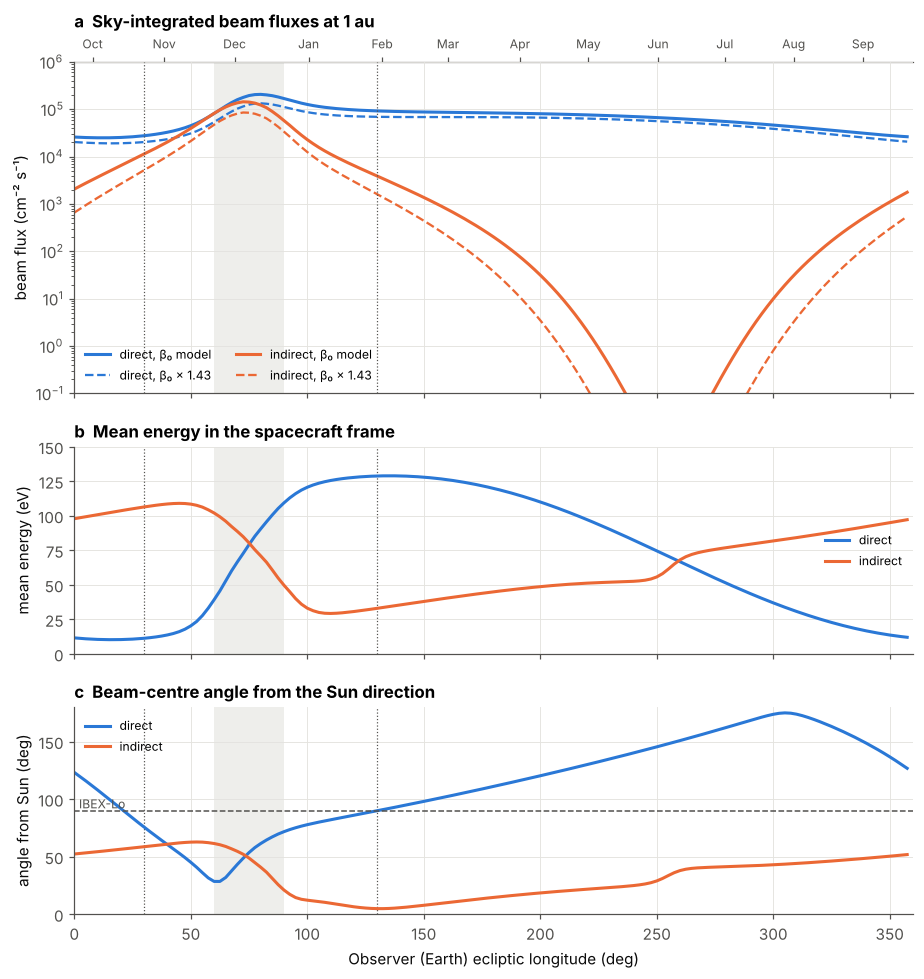

In [5]:
cen_d, cen_i = ann["cen_dir"], ann["cen_ind"]
sep = angular_distance(cen_d[:, 0], cen_d[:, 1], cen_i[:, 0], cen_i[:, 1])
sun_lon = (L + 180) % 360
piv_d = angular_distance(sun_lon, 0 * L, cen_d[:, 0], cen_d[:, 1])
piv_i = angular_distance(sun_lon, 0 * L, cen_i[:, 0], cen_i[:, 1])
blend = sep < (cen_d[:, 2] + cen_i[:, 2])   # centroids closer than the summed RMS widths

def shade_blend(ax):
    y0, y1 = ax.get_ylim()
    ax.fill_between(L, y0, y1, where=blend, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.set_ylim(y0, y1)

fig, axes = plt.subplots(3, 1, figsize=(8.5, 9), sharex=True,
                         gridspec_kw=dict(height_ratios=[1.6, 1, 1]))
ax = axes[0]
for F, col, name in [(Fd, C_DIR, "direct"), (Fi, C_IND, "indirect")]:
    ax.plot(L, log_interp_beta(B, F, BETA_MODEL), color=col, label=f"{name}, β₀ model")
    ax.plot(L, log_interp_beta(B, F, BETA_ENH), color=col, ls="--", lw=1.5,
            label=f"{name}, β₀ × 1.43")
ax.set_yscale("log"); ax.set_ylim(1e-1, 1e6)
ax.set_ylabel("beam flux (cm⁻² s⁻¹)")
ax.legend(fontsize=8, ncol=2, loc="lower left")
ax.set_title("a  Sky-integrated beam fluxes at 1 au")
for x in (LON_DIR, LON_IND):
    for a in axes:
        a.axvline(x, color=INK2, lw=0.8, ls=":")
shade_blend(ax); add_month_axis(ax)

ax = axes[1]
ax.plot(L, ann["E_dir"], color=C_DIR, label="direct")
ax.plot(L, ann["E_ind"], color=C_IND, label="indirect")
ax.set_ylabel("mean energy (eV)"); ax.set_ylim(0, 150)
ax.legend(fontsize=8, loc="center right")
ax.set_title("b  Mean energy in the spacecraft frame"); shade_blend(ax)

ax = axes[2]
ax.plot(L, piv_d, color=C_DIR, label="direct")
ax.plot(L, piv_i, color=C_IND, label="indirect")
ax.axhline(90, color=INK2, lw=1, ls="--"); ax.text(2, 92, "IBEX-Lo", fontsize=8, color=INK2)
ax.set_ylim(0, 180); ax.set_ylabel("angle from Sun (deg)")
ax.set_xlabel("Observer (Earth) ecliptic longitude (deg)")
ax.set_title("c  Beam-centre angle from the Sun direction"); ax.legend(fontsize=8, loc="upper left")
shade_blend(ax)
ax.set_xlim(0, 360)
fig.tight_layout(); save(fig, "fig4_annual_beams")

## Fig. 5 — Why the ratio measures β₀

(a) Flux-weighted mean exposure ⟨X⟩ = −d ln F / dβ₀ of each beam. The
indirect beam accumulates 2–4× more exposure than the direct one in the
seasons where it is observable. (b) How each observable responds to the two
competing explanations of the SWAP result: H1 — ionization 43% higher at fixed
density; H2 — density 43% higher at the model ionization rate (same pickup-ion
production n·β). The absolute direct-beam flux distinguishes them only if the
detector's absolute efficiency is known to better than tens of percent; the
ratio does not need it.

<X>_dir(130) = 6.661e+06 s, <X>_ind(30) = 1.832e+07 s
responses: {'H1: β₀ × 1.43': [0.751, 0.457, 0.608], 'H2: n × 1.43': [1.43, 1.43, 1.0]}


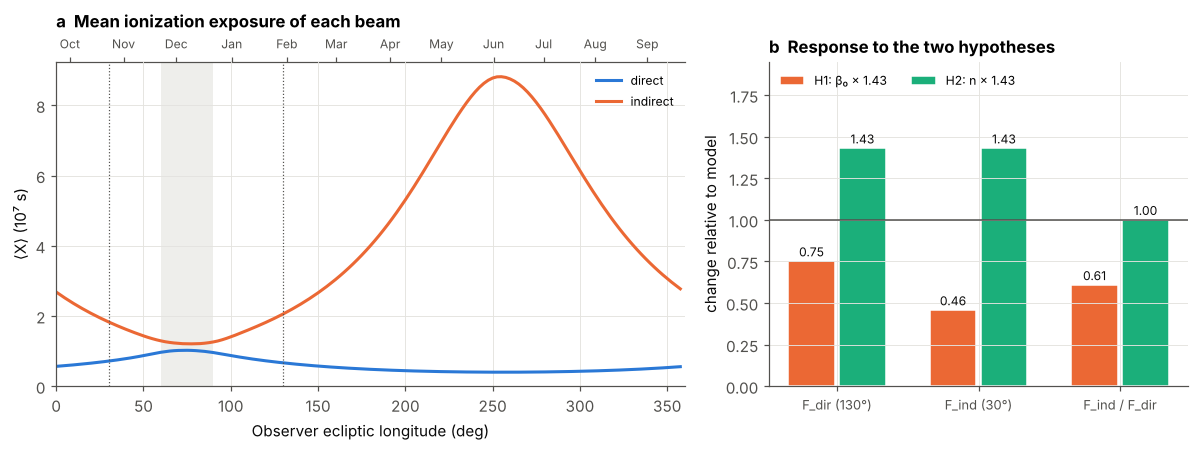

In [6]:
Xd = effective_exposure(B, Fd, BETA_MODEL)
Xi = effective_exposure(B, Fi, BETA_MODEL)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
ax.plot(L, Xd / 1e7, color=C_DIR, label="direct")
ax.plot(L, Xi / 1e7, color=C_IND, label="indirect")
ax.set_ylabel("⟨X⟩ (10⁷ s)"); ax.set_xlabel("Observer ecliptic longitude (deg)")
ax.set_xlim(0, 360); ax.set_ylim(0, None)
for x in (LON_DIR, LON_IND):
    ax.axvline(x, color=INK2, lw=0.8, ls=":")
ax.legend(fontsize=8); ax.set_title("a  Mean ionization exposure of each beam")
y0, y1 = ax.get_ylim()
ax.fill_between(L, y0, y1, where=blend, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.set_ylim(y0, y1)
add_month_axis(ax)

fd0 = log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_MODEL)
fi0 = log_interp_beta(B, at_lon(Fi, LON_IND), BETA_MODEL)
fd1 = log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_ENH)
fi1 = log_interp_beta(B, at_lon(Fi, LON_IND), BETA_ENH)
resp = {"H1: β₀ × 1.43": [fd1 / fd0, fi1 / fi0, (fi1 / fd1) / (fi0 / fd0)],
        "H2: n × 1.43":  [ENH, ENH, 1.0]}
labels = [f"F_dir ({LON_DIR:.0f}°)", f"F_ind ({LON_IND:.0f}°)", "F_ind / F_dir"]
ax = axes[1]
x = np.arange(3); w = 0.36
for k, (name, vals) in enumerate(resp.items()):
    bars = ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=[C_IND, C_ALT][k],
                  label=name, edgecolor="white", linewidth=1)
    for xi_, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi_, v + 0.03, f"{v:.2f}", ha="center", fontsize=8, color=INK)
ax.axhline(1, color=INK2, lw=1)
ax.set_xticks(x, labels, fontsize=8.5); ax.set_ylabel("change relative to model")
ax.set_ylim(0, 1.95); ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.set_title("b  Response to the two hypotheses")
fig.tight_layout(); save(fig, "fig5_exposure_response")
print(f"<X>_dir({LON_DIR:.0f}) = {at_lon(Xd, LON_DIR):.3e} s, <X>_ind({LON_IND:.0f}) = {at_lon(Xi, LON_IND):.3e} s")
print("responses:", {k: np.round(v, 3).tolist() for k, v in resp.items()})

## Fig. 6 — Breaking the density–ionization degeneracy

Asimov (noise-free) pseudo-data generated under H1 (β₀ = 1.43×10⁻⁷ s⁻¹) with
10⁴ counts in the February direct beam; the October indirect-beam counts
follow from the same exposure time and efficiency. Parameters: ionization rate
β₀ and the product n_ISN·ε of density and unknown absolute efficiency.
Contours: Δχ² = 2.30, 6.18, 11.8 (1, 2, 3σ for two parameters, Poisson
likelihood of Baker & Cousins 1984). The direct beam alone constrains only a
curve in this plane; adding the indirect beam closes the contour. The cross
marks H2 rescaled to match the direct-beam counts.

indirect counts: 749; beta0 1-sigma range: 1.400-1.460 e-7 s^-1
H2 excluded at delta chi^2 = 220.0 (14.8 sigma, 1 dof)


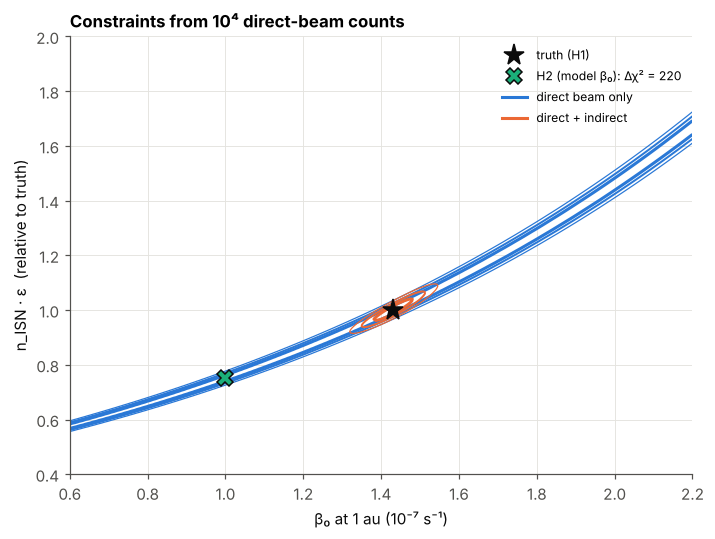

In [7]:
N_DIR_TRUE = 1.0e4
fd_t = log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_ENH)
fi_t = log_interp_beta(B, at_lon(Fi, LON_IND), BETA_ENH)
K = N_DIR_TRUE / fd_t                      # counts per unit flux (same for both seasons)
obs = np.array([N_DIR_TRUE, K * fi_t])

b_grid = np.linspace(0.6e-7, 2.2e-7, 241)
s_grid = np.linspace(0.4, 2.0, 241)        # n*eps relative to truth
fd_g = log_interp_beta(B, at_lon(Fd, LON_DIR), b_grid)
fi_g = log_interp_beta(B, at_lon(Fi, LON_IND), b_grid)
md_counts = K * s_grid[:, None] * fd_g[None, :]
mi_counts = K * s_grid[:, None] * fi_g[None, :]
chi_dir = poisson_deviance(md_counts[..., None], np.array([obs[0]]))
chi_both = poisson_deviance(np.stack([md_counts, mi_counts], -1), obs)
levels = [2.30, 6.18, 11.8]

# H2 point: model beta, scale chosen to reproduce the direct counts
s_h2 = N_DIR_TRUE / (K * log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_MODEL))
chi_h2 = poisson_deviance(np.array([N_DIR_TRUE, K * s_h2 * log_interp_beta(B, at_lon(Fi, LON_IND), BETA_MODEL)]), obs)

fig, ax = plt.subplots(figsize=(6.6, 5))
ax.contour(b_grid * 1e7, s_grid, chi_dir, levels=levels, colors=C_DIR,
           linewidths=[2, 1.3, 0.8])
ax.contour(b_grid * 1e7, s_grid, chi_both, levels=levels, colors=C_IND,
           linewidths=[2, 1.3, 0.8])
ax.plot(BETA_ENH * 1e7, 1.0, "*", ms=14, color=INK, label="truth (H1)")
ax.plot(BETA_MODEL * 1e7, s_h2, "X", ms=10, color=C_ALT, mec=INK,
        label=f"H2 (model β₀): Δχ² = {chi_h2:.0f}")
ax.plot([], [], color=C_DIR, label="direct beam only")
ax.plot([], [], color=C_IND, label="direct + indirect")
ax.set_xlabel("β₀ at 1 au (10⁻⁷ s⁻¹)")
ax.set_ylabel("n_ISN · ε  (relative to truth)")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Constraints from 10⁴ direct-beam counts")
fig.tight_layout(); save(fig, "fig6_degeneracy")

# 1-sigma marginal error on beta0 from the combined fit (profile over n*eps)
prof = chi_both.min(axis=0)
inside = b_grid[prof - prof.min() < 1.0]
print(f"indirect counts: {obs[1]:.0f}; beta0 1-sigma range: {inside.min()*1e7:.3f}-{inside.max()*1e7:.3f} e-7 s^-1")
print(f"H2 excluded at delta chi^2 = {chi_h2:.1f} ({np.sqrt(chi_h2):.1f} sigma, 1 dof)")

## Fig. 7 — Observing season, systematics and required statistics

The direct beam is fixed at the February peak (Earth at 130°); the indirect
beam observation season is varied through the autumn.

(a) Signal: change of ln(F_ind/F_dir) from a 43% higher β₀, versus the change
from perturbing one inflow parameter at a time (±0.5 km/s, ±500 K, ±0.5° in
longitude and latitude; half the ± difference is shown). These perturbation
sizes are generous test values, not literature uncertainties.
(b) Indirect-beam counts needed to detect the signal at 3σ from counting
statistics alone (equal exposure for the two seasons), with the mean energy of
the indirect beam for reference.

lon   0.0: signal -0.855, sys 0.062, S/sys  13.9, N_ind(3sigma)      13
lon   5.0: signal -0.784, sys 0.058, S/sys  13.5, N_ind(3sigma)      15
lon  10.0: signal -0.718, sys 0.055, S/sys  13.0, N_ind(3sigma)      18
lon  15.0: signal -0.657, sys 0.053, S/sys  12.5, N_ind(3sigma)      22
lon  20.0: signal -0.600, sys 0.050, S/sys  11.9, N_ind(3sigma)      27
lon  25.0: signal -0.547, sys 0.048, S/sys  11.3, N_ind(3sigma)      33
lon  30.0: signal -0.497, sys 0.047, S/sys  10.6, N_ind(3sigma)      41
lon  35.0: signal -0.451, sys 0.046, S/sys   9.8, N_ind(3sigma)      52
lon  40.0: signal -0.407, sys 0.046, S/sys   8.8, N_ind(3sigma)      66
lon  45.0: signal -0.366, sys 0.047, S/sys   7.8, N_ind(3sigma)      87
lon  50.0: signal -0.328, sys 0.048, S/sys   6.9, N_ind(3sigma)     119
lon  55.0: signal -0.295, sys 0.047, S/sys   6.3, N_ind(3sigma)     167


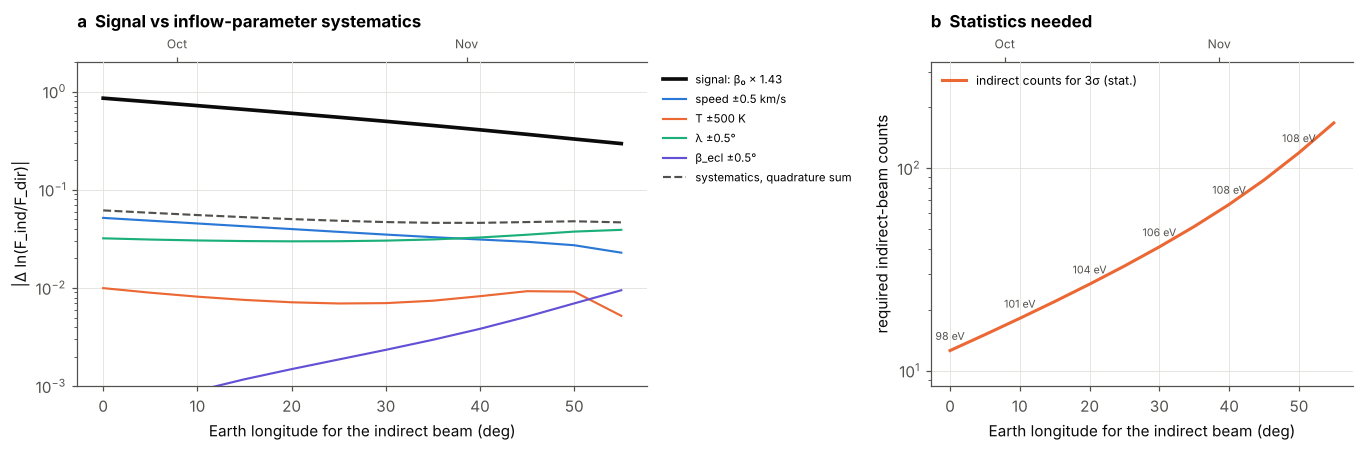

In [8]:
sysd = np.load(DATA / "systematics.npz")
names = list(sysd["names"]); Ls, Bs = sysd["obs_lons"], sysd["betas"]
def lnR(var, lon_i, beta):
    k = names.index(var)
    i = int(np.argmin(np.abs(Ls - lon_i))); j = int(np.argmin(np.abs(Ls - LON_DIR)))
    fi = log_interp_beta(Bs, sysd["F_ind"][k, i], beta)
    fd = log_interp_beta(Bs, sysd["F_dir"][k, j], beta)
    return np.log(fi / fd)

autumn = Ls[(Ls >= 0) & (Ls <= 55)]   # beams blend beyond ~60 deg (Fig. 4)
signal = np.array([lnR("baseline", l, BETA_ENH) - lnR("baseline", l, BETA_MODEL) for l in autumn])
sys_terms = {}
for p_, lab in [("speed", "speed ±0.5 km/s"), ("temp", "T ±500 K"),
                ("lon", "λ ±0.5°"), ("lat", "β_ecl ±0.5°")]:
    sys_terms[lab] = np.array([0.5 * (lnR(p_ + "+", l, BETA_MODEL) - lnR(p_ + "-", l, BETA_MODEL))
                               for l in autumn])
sys_tot = np.sqrt(sum(v**2 for v in sys_terms.values()))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axes[0]
ax.plot(autumn, np.abs(signal), color=INK, lw=2.4, label="signal: β₀ × 1.43")
grays = [C_DIR, C_IND, C_ALT, "#6250d6"]
for (lab, v), col in zip(sys_terms.items(), grays):
    ax.plot(autumn, np.abs(v), color=col, lw=1.4, label=lab)
ax.plot(autumn, sys_tot, color=INK2, lw=1.4, ls="--", label="systematics, quadrature sum")
ax.set_xlabel("Earth longitude for the indirect beam (deg)")
ax.set_ylabel("|Δ ln(F_ind/F_dir)|"); ax.set_yscale("log"); ax.set_ylim(1e-3, 2)
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1.0)); ax.set_title("a  Signal vs inflow-parameter systematics")
add_month_axis(ax)

ax = axes[1]
ratio_counts = np.array([np.exp(lnR("baseline", l, BETA_MODEL)) for l in autumn])
need = counts_needed(signal, 3.0, ratio_counts)
ax.plot(autumn, need, color=C_IND, label="indirect counts for 3σ (stat.)")
ax.set_yscale("log"); ax.set_ylim(need.min() / 1.5, need.max() * 2); ax.set_ylabel("required indirect-beam counts")
ax.set_xlabel("Earth longitude for the indirect beam (deg)")
ax.set_title("b  Statistics needed")
for l_, n_ in zip(autumn[::2], need[::2]):
    E_ = at_lon(ann["E_ind"], l_)
    ax.annotate(f"{E_:.0f} eV", (l_, n_), xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=7, color=INK2)
ax.legend(fontsize=8, loc="upper left")
add_month_axis(ax)
fig.tight_layout(); save(fig, "fig7_season_systematics")

for l_, s_, t_, n_ in zip(autumn, signal, sys_tot, need):
    print(f"lon {l_:5.1f}: signal {s_:+.3f}, sys {t_:.3f}, S/sys {abs(s_)/t_:5.1f}, N_ind(3sigma) {n_:7.0f}")

## Fig. 8 — Energy threshold

IMAP-Lo detects helium indirectly (sputtering), with an efficiency that falls
at low energy. The indirect beam in autumn is fast enough (~100 eV) to be
nearly unaffected by a threshold of a few tens of eV, while the slow
"direct" population seen in autumn from behind (~10–20 eV) is removed.

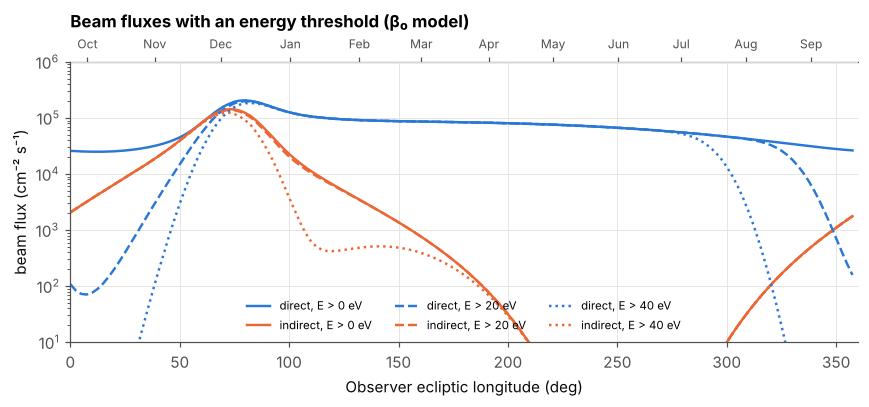

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ls_ = ["-", "--", ":"]
for k, em in enumerate(EMINS):
    ax.plot(L, log_interp_beta(B, Fd_all[k], BETA_MODEL), color=C_DIR, ls=ls_[k % 3], lw=1.6,
            label=f"direct, E > {em:.0f} eV")
    ax.plot(L, log_interp_beta(B, Fi_all[k], BETA_MODEL), color=C_IND, ls=ls_[k % 3], lw=1.6,
            label=f"indirect, E > {em:.0f} eV")
ax.set_yscale("log"); ax.set_ylim(1e1, 1e6); ax.set_xlim(0, 360)
ax.set_xlabel("Observer ecliptic longitude (deg)"); ax.set_ylabel("beam flux (cm⁻² s⁻¹)")
ax.legend(fontsize=7.5, ncol=3, loc="lower center"); add_month_axis(ax)
ax.set_title("Beam fluxes with an energy threshold (β₀ model)")
fig.tight_layout(); save(fig, "fig8_energy_threshold")

## Summary numbers

In [10]:
i_l = LON_IND
rows = [
    ("model β₀ at 1 au", f"{BETA_MODEL:.2e} s⁻¹"),
    ("upwind density at 1 au (β₀ model)", f"{den['n_all'][np.argmin(np.abs(lons_d-P.lon)), jm]:.4f} cm⁻³"),
    (f"direct beam energy at {LON_DIR:.0f}°", f"{at_lon(ann['E_dir'], LON_DIR):.0f} eV"),
    (f"indirect beam energy at {i_l:.0f}°", f"{at_lon(ann['E_ind'], i_l):.0f} eV"),
    ("⟨X⟩ direct / indirect", f"{at_lon(Xd, LON_DIR):.2e} / {at_lon(Xi, i_l):.2e} s"),
    ("F_ind/F_dir change for β₀ × 1.43", f"{resp['H1: β₀ × 1.43'][2]:.3f}"),
    ("pivot angle for indirect beam", f"{at_lon(piv_i, i_l):.0f}°"),
]
w = max(len(r[0]) for r in rows)
for a, b in rows:
    print(f"{a:<{w}}  {b}")

model β₀ at 1 au                   1.00e-07 s⁻¹
upwind density at 1 au (β₀ model)  0.0112 cm⁻³
direct beam energy at 130°         129 eV
indirect beam energy at 30°        106 eV
⟨X⟩ direct / indirect              6.66e+06 / 1.83e+07 s
F_ind/F_dir change for β₀ × 1.43   0.608
pivot angle for indirect beam      59°
